# Polynomial Regression

This notebook demonstrates **Polynomial Regression** in two parts:

1. A small toy dataset (Experience vs Salary) to visually compare **Linear Regression** vs **Polynomial Regression**.
2. A real-world dataset (`insurance.csv`) used to build a **multiple linear regression** model that predicts medical insurance charges, including categorical feature encoding and a simple prediction demo on user input.


## Part 1: Linear vs Polynomial Regression (Toy Dataset)

### Imports
Load the libraries needed for data handling, plotting, and modeling.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures


### Create the Dataset
A small synthetic dataset relating years of experience to salary, which clearly does **not** follow a straight line.

In [2]:
data = pd.DataFrame({'Experience':[1,2,3,4,5,6,7], 'Salary':[50000,55000,65000,80000,110000,150000,200000]})

In [33]:
data

,Experience,Salary
0,1,50000
1,2,55000
2,3,65000
3,4,80000
4,5,110000
5,6,150000
6,7,200000


### Visualize the Raw Data
Plot Experience vs Salary to see the non-linear trend.

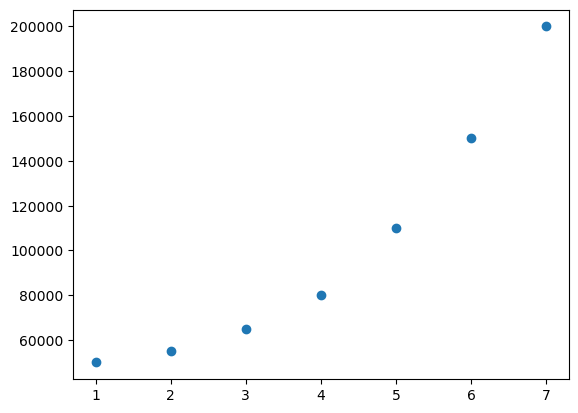

In [8]:
plt.scatter(x=data.Experience, y=data.Salary)

### Fit a Simple Linear Regression Model
Train a plain `LinearRegression` model on the data as a baseline.

In [13]:
X= data[['Experience']]
y=data.Salary

In [14]:
lin = LinearRegression()
lin.fit(X, y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [15]:
y_pred = lin.predict(X)

### Compare Linear Predictions to Actual Data
The straight-line fit struggles to capture the curve in the data.

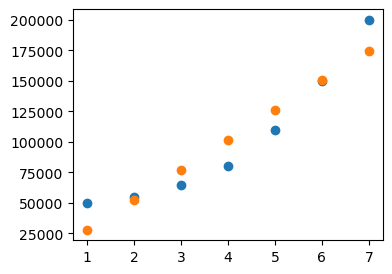

In [17]:
plt.figure(figsize=(4,3))
plt.scatter(x=data.Experience, y=data.Salary)
plt.scatter(x=data.Experience, y=y_pred)

### Apply Polynomial Features (Degree 3)
Transform the single feature into polynomial terms (`x`, `x^2`, `x^3`) so a linear model can fit a curved relationship.

In [27]:
poly = PolynomialFeatures(degree=3)
X_poly = poly.fit_transform(X)

poly.get_feature_names_out()

array(['1', 'Experience', 'Experience^2', 'Experience^3'], dtype=object)

### Fit Linear Regression on Polynomial Features
Now fit `LinearRegression` on the transformed (polynomial) features — this is what makes it "polynomial regression".

In [28]:
# poly.fit(X_poly, y)
lin2 = LinearRegression()
lin2.fit(X_poly, y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [29]:
y_pred = lin2.predict(X_poly)

### Compare Polynomial Predictions to Actual Data
The polynomial fit tracks the curve in the data much more closely than the simple linear model.

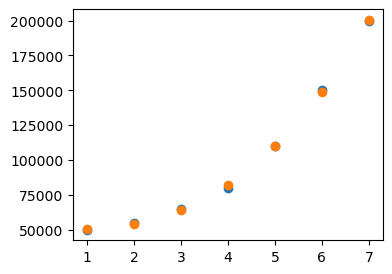

In [30]:
plt.figure(figsize=(4,3))
plt.scatter(x=data.Experience,y=data.Salary)
plt.scatter(x=data.Experience, y=y_pred)

## Part 2: Predicting Insurance Charges (Real Dataset)

This part moves to a real dataset, `insurance.csv`, and builds a regression model to predict medical insurance **charges** from patient attributes (age, sex, BMI, children, smoker status, region).

### Load the Dataset

In [129]:
data = pd.read_csv('insurance.csv')

In [130]:
data

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


### Inspect the Data
Check column types and non-null counts.

In [131]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


### Check for Duplicate Rows

In [132]:
data.duplicated().sum()

np.int64(1)

### Remove Duplicates and Reset the Index

In [133]:
data.drop_duplicates(inplace=True)

In [135]:
data.reset_index(drop=True,inplace=True)

In [137]:
data.tail()

,age,sex,bmi,children,smoker,region,charges
1332,50,male,30.97,3,no,northwest,10600.5483
1333,18,female,31.92,0,no,northeast,2205.9808
1334,18,female,36.85,0,no,southeast,1629.8335
1335,21,female,25.80,0,no,southwest,2007.9450
1336,61,female,29.07,0,yes,northwest,29141.3603


### Split Features and Target
Separate the input features (`X`) from the target variable (`charges`).

In [138]:
X= data.drop('charges',axis=1)
y = data.charges

In [139]:
X.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region'], dtype='object')

### Separate Categorical and Numerical Columns
Categorical columns (`sex`, `smoker`, `region`) need encoding before they can be used in a regression model; numerical columns can be used as-is.

In [140]:
cat_cols = data.select_dtypes('object')
num_cols = data.select_dtypes('number')

In [141]:
cat_cols

,sex,smoker,region
0,female,yes,southwest
1,male,no,southeast
2,male,no,southeast
3,male,no,northwest
4,male,no,northwest
...,...,...,...
1332,male,no,northwest
1333,female,no,northeast
1334,female,no,southeast
1335,female,no,southwest


### One-Hot Encode Categorical Columns
Convert categorical text columns into numerical (0/1) columns using `OneHotEncoder`.

In [142]:
from sklearn.preprocessing import OneHotEncoder

In [143]:
ohe = OneHotEncoder()
encoded= ohe.fit_transform(cat_cols)

In [144]:
encoded = encoded.toarray()

In [145]:
ohe.get_feature_names_out()

array(['sex_female', 'sex_male', 'smoker_no', 'smoker_yes',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest'], dtype=object)

In [146]:
encoded = pd.DataFrame(data=encoded, columns=ohe.get_feature_names_out())
encoded

,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest
0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
2,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
3,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
4,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...
1332,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
1333,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
1334,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1335,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


### Combine Encoded and Numerical Columns
Merge the one-hot encoded categorical columns with the original numerical columns into a single feature set ready for modeling.

In [147]:
final_data = pd.concat([encoded,num_cols],axis=1)

In [148]:
final_data

,sex_female,sex_male,smoker_no,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest,age,bmi,children,charges
0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,19,27.900,0,16884.92400
1,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,18,33.770,1,1725.55230
2,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,28,33.000,3,4449.46200
3,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,33,22.705,0,21984.47061
4,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,32,28.880,0,3866.85520
...,...,...,...,...,...,...,...,...,...,...,...,...
1332,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,50,30.970,3,10600.54830
1333,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,18,31.920,0,2205.98080
1334,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,18,36.850,0,1629.83350
1335,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,21,25.800,0,2007.94500


In [149]:
data.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

### Try a Prediction on New Input
Takes a new patient's details as input, builds the same one-hot encoding used during training, and shows the encoded feature vector that would be fed into a trained model to predict their insurance charges.

> **Note:** This cell uses `input()`, so it expects manual entry when run interactively.

In [151]:
age = int(input("AGE:"))
sex = input('Gender:')
bmi = float(input("BMI"))
children = int(input("Children"))
smoker   = input("Smoker: ")
region   = input("REgion")
record = pd.DataFrame({'age':[age],
                       'sex':[sex],
                        'bmi':[bmi],
                        'children':[children], 
                        'smoker':[smoker], 
                        'region':[region]})

AGE: 23
Gender: male
BMI 26
Children 3
Smoker:  yes
REgion southwest


In [152]:
record

,age,sex,bmi,children,smoker,region
0,23,male,26.0,3,yes,southwest


In [154]:
ohe.transform(record[['sex','smoker', 'region']]).toarray()

array([[0., 1., 0., 1., 0., 0., 0., 1.]])

In [155]:
ohe.get_feature_names_out()

array(['sex_female', 'sex_male', 'smoker_no', 'smoker_yes',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest'], dtype=object)